# Hamiltonian Monte Carlo for the 2D XY model
**Running this notebook:** the default runs the original lightweight assertions
and a small example. Set `RUN_LONG_EXPERIMENTS = True` below to rerun the energy-error
diagnostic, hot/cold comparison and beta/finite-size scans. Their original run
lengths and analysis are retained. All dependent experiment plots are also guarded.

**Saved outputs:** the original figures and printed results are retained, including
when their cells are skipped. They predate the seeds added during GitHub preparation;
these seeds reproduce future runs in a matching environment, not the saved chains.
Raw measurement arrays from the original runs were not saved. Read the scientific
notes at the end before interpreting the finite-size results.


In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 
import tqdm.auto as tqdm
from numbers import Integral, Real


In [ ]:
# Change this flag only when you intend to rerun the longer experiments.
RUN_LONG_EXPERIMENTS = False
SEED = 20261027


def set_seed(seed):
    """Seed NumPy and PyTorch's global RNGs for subsequent draws (CPU runs here)."""
    if isinstance(seed, bool) or not isinstance(seed, Integral) or not 0 <= seed < 2**32:
        raise ValueError("seed must be an integer in [0, 2**32)")
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))


def _positive_integer(name, value):
    if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
        raise ValueError(f"{name} must be a positive integer")


def _finite_real(name, value, *, minimum=None, strict=False):
    if isinstance(value, bool) or not isinstance(value, Real) or not np.isfinite(value):
        raise ValueError(f"{name} must be a finite real number")
    if minimum is not None and (value < minimum or (strict and value == minimum)):
        comparison = "greater than" if strict else "at least"
        raise ValueError(f"{name} must be {comparison} {minimum}")


set_seed(SEED)


In [2]:
def grab(x):
    """grabs a tensor and coverts it to numpy"""
    return x.detach().cpu().numpy() #If the tensor has a gradient graph it gets detached from it(like to run backpropagation), and it is moved to cpu where numpy operations happen. Numpy won't accept a tensor if it's attached to a gradient graph. 

### Define Euclidian action(t -> it in lattice field theory)

In [3]:
class XY_Action():
    def __init__(self, *, J = 1.0, beta = 1.0):
        _finite_real("J", J)
        _finite_real("beta", beta, minimum=0)
        self.J = J
        self.beta = beta
        self.grad = torch.func.grad(self.value)
    def energy(self, theta):
        """Calculates the energy associated to a given configuration"""
        diff_x = theta - torch.roll(theta, shifts = -1, dims=1) 
        diff_y = theta - torch.roll(theta, shifts = -1, dims = 0)
        E = - self.J * (torch.cos(diff_x).sum() + torch.cos(diff_y).sum())
        return E
    def value(self,theta):
        return self.beta*self.energy(theta)


### Vortices and Winding numbers

In [4]:
def wrap(theta):
    """
    Wrap angles so that they always stay in the boundar [-pi, pi)
    """
    theta_wrapped = ( (theta + np.pi) % (2*np.pi) )  - np.pi
    
    return theta_wrapped

In [5]:
def vortex_charge_field_raw(theta):
    """
    Calculate vortex charge for each plaquette on the lattice, without rounding values for debugging and testing.
    For an L x L lattice, there are L^2 plaquettes so L^2 vortex charges
    """

    theta_left = torch.roll(theta, shifts = 1, dims = 1)

    theta_below = torch.roll(theta, shifts = -1, dims = 0)

    diff_x = wrap(theta - theta_left)
    diff_y = wrap(theta - theta_below)
    
    #collect vortex charges for each plaquette
    q_list = []

    L = theta.shape[0]

    for i in range(L):
        for j in range(L):

            l = (i + 1) % L
            k = (j + 1) % L

            q = (diff_x[l, k] + diff_y[i, k] - diff_x[i, k] - diff_y[i, j]) / (2*np.pi)
            q_list.append(q)
        
    #turn the list into a field of vortex charges of shape L x L 
    q_tensor = torch.stack(q_list).reshape(theta.shape)
    
    return q_tensor

#### Verify vortex code. For an alligned configuration, the vortex charge should be zero at each plaquette. The sum of all vortex charges should also be zero, charges should also be rotational invariant. 

In [6]:
theta_zeros = torch.zeros(8, 8)

#Raise error if charge is not zero everywhere
assert torch.allclose(
    vortex_charge_field_raw(theta_zeros),
    torch.zeros_like(theta_zeros),
    atol=1e-6,
), "Vortex charges should all be zero for a zero-angle lattice."

In [7]:
#Verify charges are rotational invariant
theta_rotated = theta_zeros + 1.234

assert torch.allclose(
    vortex_charge_field_raw(theta_rotated),
    vortex_charge_field_raw(theta_zeros),
    atol=1e-6,
),"Vortex charges should stay the same after a global rotation, vortex charge is not implemented correctly."

In [8]:
#By adding a vortex manually, verify that it's calculated correctly

theta_vortex = torch.zeros(8, 8)

theta_vortex[0,0] = 3 * np.pi / 2 #this should be wrapped to pi/2 when subtracted to zero and also when we subtract pi/2 from it.
theta_vortex[1, 0] = 0
theta_vortex [1, 1] = np.pi / 2
theta_vortex[0, 1] = np.pi

#The values above should add up to 1 so the first plaquette at position (0, 0) of the field should have charge 1
assert torch.isclose(
    vortex_charge_field_raw(theta_vortex)[0, 0],
    torch.tensor(1.0),
    atol = 1e-6
), "Either wrapping function or vortex charge fucntion are not implemented correctly, there shoudl be a vortes at index [0, 0] of the vortex field."

In [9]:
#Verify that summing all charges gives zero since for each vortex there should be an anti-vortex that cancels its charge out. 

theta_test = torch.rand(8, 8) * 2 * np.pi

#Add negative charge to see if everything works as espected also in that case
theta_test[0,0] = -3 * np.pi / 2 
theta_test[1, 0] = 0
theta_test [1, 1] = -np.pi / 2
theta_test[0, 1] = -np.pi


q_field = vortex_charge_field_raw(theta_test)

q_sum = q_field.sum()

assert torch.isclose(
    q_sum, 
    torch.tensor(0.0),
    atol = 1e-6
), "Charges don't sum up to zero, there must be an error in the vortex field function "

assert torch.isclose(
    q_field[0, 0],
    torch.tensor(-1.0),
    atol = 1e-6
), "Either wrapping function or vortex charge fucntion are not implemented correctly, there shoudl be a vortes at index [0, 0] of the vortex field."


#### Once the tests are passed define a charge field function with integer charge values and define a function to calculate the density of vortices in a configuration

In [10]:
def vortex_charge_field(theta):
    """
    Calculate integer vortex charge for each plaquette.
    """
    q_raw = vortex_charge_field_raw(theta)
    
    return torch.round(q_raw)

In [11]:
def vortex_density(charge_field):
    
    density = abs(charge_field).sum() / torch.numel(charge_field)

    return density

In [12]:
charge_field = vortex_charge_field(theta_vortex)

vortex_num = vortex_density(charge_field) * torch.numel(charge_field)

assert torch.isclose(
    vortex_num, 
    torch.tensor(2.0),
    atol=1e-6
), "There should be 2 vortices, either the density function is wrong or the charge field is wrong."


#### Compute winding numbers

In [13]:
def winding_raw(theta):
    """
    Find winding number for each row and column without rounding to integer 
    """

    theta_left = torch.roll(theta, shifts = 1, dims = 1)
    theta_below = torch.roll(theta, shifts = -1, dims = 0)

    diff_x = wrap(theta - theta_left) / (2 * np.pi)
    diff_y = wrap(theta - theta_below) / (2 * np.pi)

    W_x = torch.sum(diff_x, dim=1)
    W_y = torch.sum(diff_y, dim=0)

    return W_x, W_y

In [14]:
theta_zeros = torch.zeros(8, 8)

W_x, W_y = winding_raw(theta_zeros)

# Check that an aligned configuration has zero winding in both directions
assert torch.allclose(
    W_x,
    torch.zeros_like(W_x),
    atol=1e-6,
), "W_x should be zero everywhere for an aligned configuration."

assert torch.allclose(
    W_y,
    torch.zeros_like(W_y),
    atol=1e-6,
), "W_y should be zero everywhere for an aligned configuration."


In [15]:
# Verify winding numbers are invariant under a global rotation

theta_test = 2 * np.pi * torch.rand(8, 8)
theta_rotated = theta_test + 1.234

W_x_original, W_y_original = winding_raw(theta_test)
W_x_rotated, W_y_rotated = winding_raw(theta_rotated)

assert torch.allclose(
    W_x_original,
    W_x_rotated,
    atol=1e-6,
), "W_x should stay unchanged after a global rotation."

assert torch.allclose(
    W_y_original,
    W_y_rotated,
    atol=1e-6,
), "W_y should stay unchanged after a global rotation."


In [16]:
# Construct a configuration with one complete 2*pi twist in the x direction

L = 8

theta_twist_x = torch.zeros(L, L)

for j in range(L):
    theta_twist_x[:, j] = 2 * np.pi * j / L

W_x, W_y = winding_raw(theta_twist_x)

# Every row winds once around the x direction
assert torch.allclose(
    torch.abs(W_x),
    torch.ones_like(W_x),
    atol=1e-6,
), "A 2*pi twist in x should give |W_x| = 1 for every row."

# There should be no winding in the y direction
assert torch.allclose(
    W_y,
    torch.zeros_like(W_y),
    atol=1e-6,
), "A pure x twist should give W_y = 0."


In [17]:
 # Construct a configuration with one complete 2*pi twist in the y direction

theta_twist_y = torch.zeros(L, L)

for i in range(L):
    theta_twist_y[i, :] = 2 * np.pi * i / L

W_x, W_y = winding_raw(theta_twist_y)

# There should be no winding in the x direction
assert torch.allclose(
    W_x,
    torch.zeros_like(W_x),
    atol=1e-6,
), "A pure y twist should give W_x = 0."

# Every column winds once around the y direction
assert torch.allclose(
    torch.abs(W_y),
    torch.ones_like(W_y),
    atol=1e-6,
), "A 2*pi twist in y should give |W_y| = 1 for every column."

In [18]:
def winding(theta):
    """
    Calculate integer winding numbers for every row and column.
    """
    W_x_raw, W_y_raw = winding_raw(theta)

    W_x = torch.round(W_x_raw)
    W_y = torch.round(W_y_raw)

    return W_x, W_y

### Helicity modulus

#### The helicity modulus measures the free-energy cost of applying a long-wavelength twist to the lattice.
#### It contains an energetic contribution from the average bond alignment and a fluctuation contribution from the sine of the bond differences.

In [19]:
def helicity_components(theta):

    diff_x = theta - torch.roll(theta, shifts = -1, dims = 1)
    diff_y = theta - torch.roll(theta, shifts = -1, dims = 0)

    cos_sum_x = torch.cos(diff_x).sum()
    cos_sum_y = torch.cos(diff_y).sum()

    sin_sum_x = torch.sin(diff_x).sum()
    sin_sum_y = torch.sin(diff_y).sum()

    return cos_sum_x, cos_sum_y, sin_sum_x, sin_sum_y

#### Calculate the helicity modulus from the ensemble of HMC measurements.
#### The fluctuation term must be calculated using averages over the whole ensemble and therefore the final helicity modulus isn't simply an observable of one individual configuration.

In [20]:
def helicity_modulus(run, action, L):

    N = L**2
    
    #store the cosine and sin sums for each configuraton in the sampling run. If we sample 1000 configurations, this should contain 1000 values. 
    cos_sum_x = run['cos_sum_x']
    cos_sum_y = run['cos_sum_y']
 
    sin_sum_x = run['sin_sum_x']
    sin_sum_y = run['sin_sum_y']


    #average energetic contribution
    cos_mean_x = cos_sum_x.mean()
    cos_mean_y = cos_sum_y.mean()


    #calculate <S^2> - <S>^2 for the fluctuation contribution. Since the XY model is symmetric, <S> = 0, so it is not necessary to include in the calculation of variance. 
    sin_variance_x = (sin_sum_x**2).mean() - sin_sum_x.mean()**2
    sin_variance_y = (sin_sum_y**2).mean() - sin_sum_y.mean()**2


    #calculate helicity modulus in each direction
    Y_x = action.J * cos_mean_x / N - action.beta * action.J**2 * sin_variance_x / N

    Y_y = action.J * cos_mean_y / N - action.beta * action.J**2 * sin_variance_y / N


    #average the two directions since the XY model is isotropic
    Y = (Y_x + Y_y) / 2

    return Y, Y_x, Y_y

### Implement update algorithm(Leapfrog), draw samples using metropoli-hastings, and build a hamiltonian Monte Carlo sampler and measure physical quantities.

In [21]:
def leapfrog(theta, pi, action, *, n_steps, dt = 0.1):
    """Use leapfrog algorithm to update the lattice angles, this makes the update symmetric and
    accurate to second order, unlike Euler which is accurate to first order"""

    _positive_integer("n_steps", n_steps)
    _finite_real("dt", dt, minimum=0, strict=True)
    if not isinstance(theta, torch.Tensor) or not isinstance(pi, torch.Tensor):
        raise ValueError("theta and pi must be tensors")
    if theta.ndim != 2 or theta.numel() == 0 or theta.shape != pi.shape:
        raise ValueError("theta and pi must be nonempty 2D tensors of the same shape")
    if not theta.is_floating_point() or theta.dtype != pi.dtype or theta.device != pi.device:
        raise ValueError("theta and pi must share a floating dtype and device")

    theta = theta + (pi * dt/2)

    for i in range (n_steps-1):
        pi = pi - action.grad(theta) * dt
        theta = theta + (pi * dt)
    
    pi = pi - action.grad(theta) * dt
    theta = theta + (pi * dt/2)

    return theta, -pi #we return the negative 'momentum' pi because the operation needs to be reversible. If we run the same leapfrog again with the new theta and new pi value, we should get values close to the old theta and pi values. This makes travelling backwards possible, while simplecticity makes the probability of going from A to B and B to A the same and hence simplifies the Metropolis-Hastings step on a theoretical level by satisfying detailed balance. In practice, since later we draw a new momentum pi for each leapfrog step, this change of sign could be omitted. 



In [22]:
def metropolis(theta_new, theta_old, pi_new, pi_old, action):
   H_old = (pi_old**2/2).sum() + action.value(theta_old)
   H_new = (pi_new**2/2).sum() + action.value(theta_new)

   dH = H_new-H_old
   
   r = torch.rand((), device = dH.device, dtype = dH.dtype) #draw scalar from uniform distribution, ensuring it's stored in the same device(cpu or gpu) as dH and that it's the same float type as dH
   if torch.log(r) < -dH:  #This ensures that configurations with lower hamiltonian are immediately accepted since log(r) <= 0, and accepts configurations with higher hamiltonian with increasingly lower probability 
       return theta_new, True
   else:
       return theta_old, False

In [23]:
def measure_xy(theta, action):
    
    #define number of lattice points and the energy of the configuration
    sites_num = theta.numel() 
    energy = action.energy(theta)

    energy_per_site = energy/sites_num
    
    #find magnetisation per site in the x and y directions
    mx = (torch.cos(theta)).mean()
    my = (torch.sin(theta)).mean()
    
    #find magnitude
    m = torch.sqrt(mx**2 + my**2)
    
    #evaluate vortices and their density 
    charge_field = vortex_charge_field(theta)
    v_density = vortex_density(charge_field)

    # Winding numbers
    W_x, W_y = winding(theta)

    #calculate the components needed to measure the helicity modulus
    cos_sum_x, cos_sum_y, sin_sum_x, sin_sum_y = helicity_components(theta)


    return{'magnetisation': m.detach().cpu(),
            'mx': mx.detach().cpu(),
            'my': my.detach().cpu(),
            'energy': energy.detach().cpu(),
            'energy_per_site': energy_per_site.detach().cpu(),
            'vortex_density': v_density.detach().cpu(),
            'winding_x': W_x.detach().cpu(),
            'winding_y': W_y.detach().cpu(),
            'cos_sum_x': cos_sum_x.detach().cpu(),
            'cos_sum_y': cos_sum_y.detach().cpu(),
            'sin_sum_x': sin_sum_x.detach().cpu(),
            'sin_sum_y': sin_sum_y.detach().cpu()}




In [24]:
def run_hmc(action, *, L = 8, start = 'cold', n_therm = 1000, n_iter = 10, dt = 0.1, n_leap = 10, n_meas = 1, seed = None):

    """Run HMC; seed optionally resets the global RNGs before initialisation.

    Record floor(n_iter / n_meas) measurements after thermalisation.
    The original requirement n_therm >= 1 is retained.
    """
    for name, value in (("L", L), ("n_therm", n_therm), ("n_iter", n_iter),
                        ("n_meas", n_meas), ("n_leap", n_leap)):
        _positive_integer(name, value)
    _finite_real("dt", dt, minimum=0, strict=True)
    if start not in ("hot", "cold"):
        raise ValueError("start must be 'hot' or 'cold'")
    if n_meas > n_iter:
        raise ValueError("n_meas must not exceed n_iter: no measurements would be recorded")
    if seed is not None:
        set_seed(seed)

    def initialise_theta(L, start):

        if start == 'cold':
            theta = torch.zeros(L, L)
        elif start == 'hot':
            theta = 2 * np.pi * torch.rand(L, L) #this draws from the uniform distribution(0 to 1), multiply by 2pi since angles of each site is between 0 and 2pi
        else:
            raise ValueError("start must be 'hot' or 'cold'")
        
        return theta
    
    
    theta = initialise_theta(L, start) #initialise configuration

    accepted_therm = 0 #record the number of accepted configurations during thermalisation. 
    energy_per_site_therm = [] #record energy for each configuration
    magnetisation_therm = [] #record magnetisation per site for each_configuration

    #Thermalisation loop, it's supposed to run enough times so that the system 'forgets' its starting distribution. 
    for i in tqdm.tqdm(range(n_therm)): 
        theta_old = theta.clone()
        pi_old = torch.randn_like(theta)
        theta_new, pi_new = leapfrog(theta_old, pi_old, action, n_steps = n_leap, dt = dt)

        theta, acceptance = metropolis(theta_new, theta_old, pi_new, pi_old, action) #record theta and whether the proposed configuration has been accepted or not
        
        accepted_therm += acceptance

        meas = measure_xy(theta, action)
        energy_per_site_therm.append(meas['energy_per_site'])
        magnetisation_therm.append(meas['magnetisation'])

    print('Thermalisation loop completed...')

    energy_per_site = []
    magnetisation = []
    vortex_density = []
    #record winding number and helicity modulus terms for each sampled configuraiton
    winding_x = []
    winding_y = []
    cos_sum_x = []
    cos_sum_y = []
    sin_sum_x = []
    sin_sum_y = []

    accepted = 0 #record number of accepted configurations after thermalisation 

    for i in tqdm.tqdm(range(n_iter)):

        theta_old = theta.clone()
        pi_old = torch.randn_like(theta)
        theta_new, pi_new = leapfrog(theta_old, pi_old, action, n_steps = n_leap, dt = dt)

        theta, acceptance = metropolis(theta_new, theta_old, pi_new, pi_old, action)
        accepted += acceptance 

        #collect measurement after a chosen number of proposed configurations  
        if (i + 1) % n_meas == 0: 
            meas = measure_xy(theta, action)
            energy_per_site.append(meas['energy_per_site'])
            magnetisation.append(meas['magnetisation'])
            vortex_density.append(meas['vortex_density'])
            winding_x.append(meas['winding_x'])
            winding_y.append(meas['winding_y'])
            cos_sum_x.append(meas['cos_sum_x'])
            cos_sum_y.append(meas['cos_sum_y'])
            sin_sum_x.append(meas['sin_sum_x'])
            sin_sum_y.append(meas['sin_sum_y'])
    
    return {'energy_per_site_therm': torch.stack(energy_per_site_therm),
            'energy_per_site':torch.stack(energy_per_site),
            'magnetisation_therm': torch.stack(magnetisation_therm),
            'magnetisation': torch.stack(magnetisation),
            'vortex_density': torch.stack(vortex_density),
            'winding_x': torch.stack(winding_x),
            'winding_y': torch.stack(winding_y),
            'acceptance_rate_therm': accepted_therm/n_therm,
            'acceptance_rate': accepted/n_iter,
            'final_theta': theta.detach().cpu().clone(),
            'cos_sum_x': torch.stack(cos_sum_x),
            'cos_sum_y': torch.stack(cos_sum_y),
            'sin_sum_x': torch.stack(sin_sum_x),
            'sin_sum_y': torch.stack(sin_sum_y)}

### Validate energy per site and magnetisation

#### When the angle magnitudes are all the same across the lattice and J = 1, the magnetisation should be 1 and the energy per site should be -2

In [25]:
action = XY_Action(J = 1.0, beta =1.0)
theta = torch.zeros(8, 8)
meas = measure_xy(theta, action)
print(meas['energy_per_site'].item())
print(meas['magnetisation'].item())

assert torch.isclose(
    meas["energy_per_site"],
    torch.tensor(-2.0),
    atol=1e-6,
), "Energy per site should be -2, correct the action and/orthe measure_xy fucntion"

assert torch.isclose(
    meas["magnetisation"],
    torch.tensor(1.0),
    atol=1e-6,
), "Magnetisation shoudl be 1, correct code in measure_xy function"


-2.0
1.0


#### Check rotational invariance. Simply rotating the whole configuration should keep the same total energy. 

In [26]:
theta_rotated = theta + 1.234

energy_original = action.energy(theta)
energy_rotated = action.energy(theta_rotated)

print(energy_original.item())
print(energy_rotated.item())

assert torch.isclose(
    energy_original, 
    energy_rotated,
    atol = 1e-6
), "The energy in the action is wrong, after a global rotation, the total energy should be the same."

-128.0
-128.0


### Test leapfrog reversibility. If the code is implemented correctly, if updating X yields Y, updating Y should yield X completely reversing the update. 

In [27]:
theta0 = 2 * np.pi * torch.rand(8, 8)
pi0 = torch.randn_like(theta0)

#run leapfrog once 
theta1, pi1 = leapfrog(
    theta0.clone(),
    pi0.clone(),
    action,
    n_steps=10,
    dt=0.05
)

#apply exactly the same transformation again
theta2, pi2 = leapfrog(
    theta1.clone(),
    pi1.clone(),
    action,
    n_steps=10,
    dt=0.05
)


#store biggest error reversibility error on the lattice
theta_error = torch.max(torch.abs(theta2 - theta0))
pi_error = torch.max(torch.abs(pi2 - pi0))

print("Maximum theta reversibility error:", theta_error.item())
print("Maximum pi reversibility error:", pi_error.item())

#raise error if there is even 1 lattice point with theta or pi differing by the chosen tolerance
#torch.allclose returns only a single boolean value unlike torch.isclose which in this case would return a boolean value for each lattice site so 8x8 = 64 values
assert torch.allclose(
    theta2, 
    theta0, 
    atol=1e-5
), "Leapfrog not implemented correctly, reversibility test not passed." 
 
assert torch.allclose(
    pi2, 
    pi0, 
    atol=1e-5
), "Leapfrog not implemented correctly, reversibility test not passed."

Maximum theta reversibility error: 4.76837158203125e-07
Maximum pi reversibility error: 4.76837158203125e-07


## A small example

A seeded $4\times4$ lattice with 20 thermalisation proposals and 40 production
proposals (five leapfrog steps each). This exercises the sampler and observables;
it is too short and too small for physical conclusions or reliable error bars.
No original experiment settings are reduced to make this example.


In [ ]:
quick_action = XY_Action(J=1.0, beta=1.0)
quick_run = run_hmc(
    quick_action, L=4, start='hot', n_therm=20, n_iter=40,
    dt=0.05, n_leap=5, n_meas=2, seed=SEED + 10
)

print(f"Measurements: {len(quick_run['energy_per_site'])}")
print(f"Acceptance rate: {quick_run['acceptance_rate']:.3f}")
print(f"Mean energy per site: {quick_run['energy_per_site'].mean().item():.4f}")
print(f"Mean magnetisation: {quick_run['magnetisation'].mean().item():.4f}")
print(f"Mean vortex density: {quick_run['vortex_density'].mean().item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(grab(quick_run['energy_per_site']), marker='.')
axes[0].set_ylabel('Energy per site')
axes[1].plot(grab(quick_run['magnetisation']), marker='.')
axes[1].set_ylabel('Magnetisation')
for ax in axes:
    ax.set_xlabel('Recorded measurement (every 2 proposals)')
plt.tight_layout()
plt.show()


#### Test leapfrog energy conservation, on a reasonable time interval energy should be conserved on average.
#### By using leapfrog, the error delta H should be proportional to dt^2 s.t on a log scale log(delta H) = const. + 2 * log(dt), so we should have a  straight line of gradient value 2. 

Slope: 2.0062753746719353


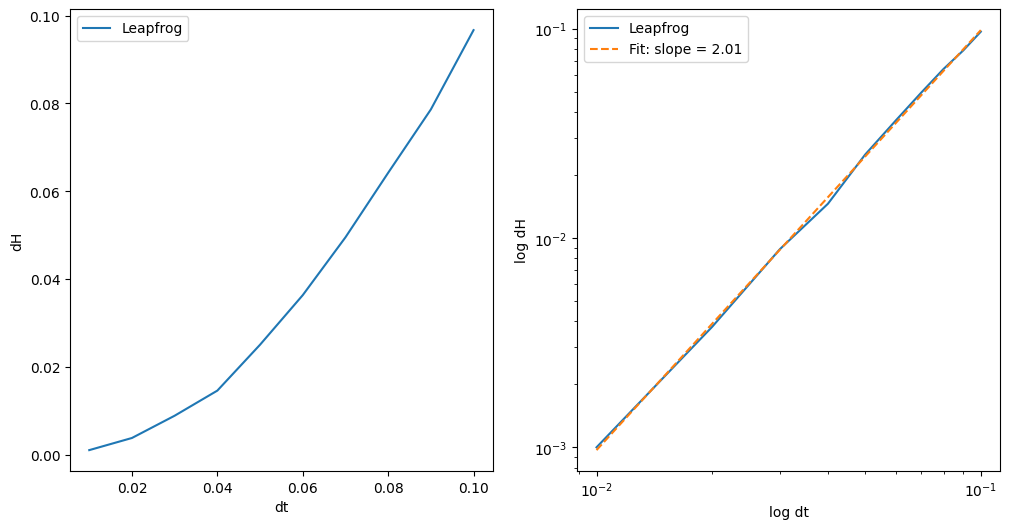

In [28]:
if RUN_LONG_EXPERIMENTS:
    set_seed(SEED + 1)

    #plot dH vs dt
    theta0 = 2 * np.pi * torch.rand(8, 8)

    dt_list = np.arange(0.01, 0.11, 0.01) #make a list of various timesteps to run the leapfrog updates
    trajectory_duration= 1.0 #choose the trajectory duration so that each time step carries the same weight i.e. in each 'experiment' for varying timestep, we travel the same amount of time. A higher trajectory duration can give more time for HMC to explore configurations so possibly reach a configuration less correlated to the previous. Shorter time means closer proposal. 

    dH = [] 

    for dt in dt_list: 

        dH_mean = [] #make a list to calculate the mean of all the trials for the same timestep
        n_steps = round(trajectory_duration / dt)
    
        for i in range(100):
            pi0 = torch.randn(8, 8)
            H0= (pi0**2/2).sum() + action.value(theta0) #define initial hamiltonian for initial pi value 

            theta_new, pi_new = leapfrog(theta0.clone(),pi0.clone(), action, n_steps=n_steps, dt=dt)
            H = (pi_new**2/2).sum() + action.value(theta_new)
            dH_mean.append(abs(H-H0))

        dH_mean = torch.stack(dH_mean).mean().item() #calculate mean

        dH.append(dH_mean)

    #calculate logaritmic values and fit line, the argument in polyfit takes the degree of the polynomial in this case '1' for a straight line. 

    log_dt = np.log(dt_list)
    log_dH = np.log(dH)

    slope, intercept = np.polyfit(log_dt, log_dH, 1)

    print(f"Slope: {slope}")
    

    fig, ax = plt.subplots(1, 2, figsize = (12, 6))

    ax[0].plot(dt_list, dH, label = 'Leapfrog')
    ax[0].set_xlabel('dt')
    ax[0].set_ylabel('dH')

    ax[1].loglog(dt_list, dH, label = 'Leapfrog')
    ax[1].set_xlabel('log dt')
    ax[1].set_ylabel('log dH')

    #Also plot the fitted line
    fitted_dH = np.exp(intercept) * dt_list**slope

    ax[1].loglog(dt_list, fitted_dH, '--', label=f'Fit: slope = {slope:.2f}')




    ax[0].legend()
    ax[1].legend()

    plt.show()



## Validation

#### Compare energy per site, magnetisation etc. for both Hot and Cold start

In [29]:
if RUN_LONG_EXPERIMENTS:
    set_seed(SEED + 2)

    cold_run = run_hmc(
        action,
        L=8,
        start='cold',
        n_therm=2000,
        n_iter=5000,
        dt=0.05,
        n_leap=20,
        n_meas=1
    )

    hot_run = run_hmc(
        action,
        L=8,
        start='hot',
        n_therm=2000,
        n_iter=5000,
        dt=0.05,
        n_leap=20,
        n_meas=1
    )

  0%|          | 0/2000 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

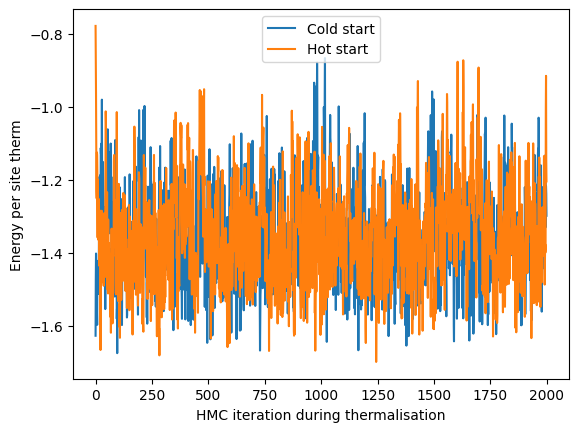

In [30]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(
        grab(cold_run['energy_per_site_therm']),
        label='Cold start'
    )

    plt.plot(
        grab(hot_run['energy_per_site_therm']),
        label='Hot start'
    )

    plt.xlabel('HMC iteration during thermalisation')
    plt.ylabel('Energy per site therm')
    plt.legend()

    plt.show()

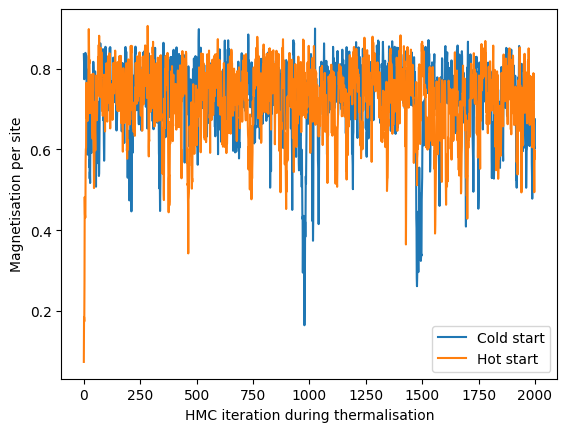

In [31]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(
        grab(cold_run['magnetisation_therm']),
        label='Cold start'
    )

    plt.plot(
        grab(hot_run['magnetisation_therm']),
        label='Hot start'
    )

    plt.xlabel('HMC iteration during thermalisation')
    plt.ylabel('Magnetisation per site')
    plt.legend()

    plt.show()

In [32]:
if RUN_LONG_EXPERIMENTS:
    print(
        "Cold energy per site:",
        cold_run['energy_per_site'].mean().item()
    )

    print(
        "Hot energy per site:",
        hot_run['energy_per_site'].mean().item()
    )

    print(
        "Cold magnetisation:",
        cold_run['magnetisation'].mean().item()
    )

    print(
        "Hot magnetisation:",
        hot_run['magnetisation'].mean().item()
    )

    print(
        "Cold acceptance:",
        cold_run['acceptance_rate']
    )

    print(
        "Hot acceptance:",
        hot_run['acceptance_rate']
    )

    Y, Y_x, Y_y = helicity_modulus(cold_run, action, L = 8)

    print(f"Helicity modulus cold run: {Y.item():.4f}")
    print(f"Helicity modulus x cold run: {Y_x.item():.4f}")
    print(f"Helicity modulus y cold run: {Y_y.item():.4f}")

Cold energy per site: -1.3629690408706665
Hot energy per site: -1.3541743755340576
Cold magnetisation: 0.7304514646530151
Hot magnetisation: 0.7238755822181702
Cold acceptance: 0.9952
Hot acceptance: 0.997
Helicity modulus cold run: 0.5776
Helicity modulus x cold run: 0.5707
Helicity modulus y cold run: 0.5846


#### Plot winding number

### Autocorrelation

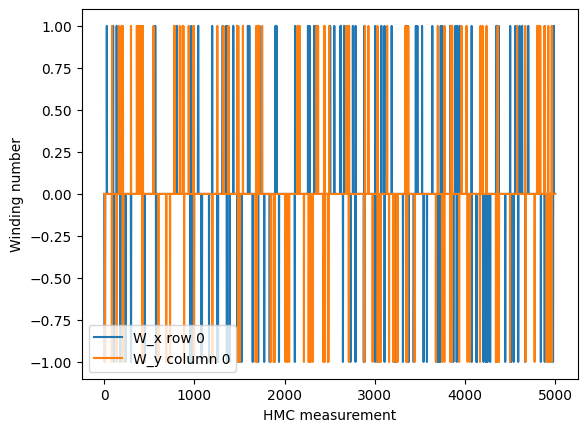

In [33]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(grab(cold_run['winding_x'][:, 0]), label='W_x row 0')
    plt.plot(grab(cold_run['winding_y'][:, 0]), label='W_y column 0')

    plt.xlabel('HMC measurement')
    plt.ylabel('Winding number')
    plt.legend()

    plt.show()

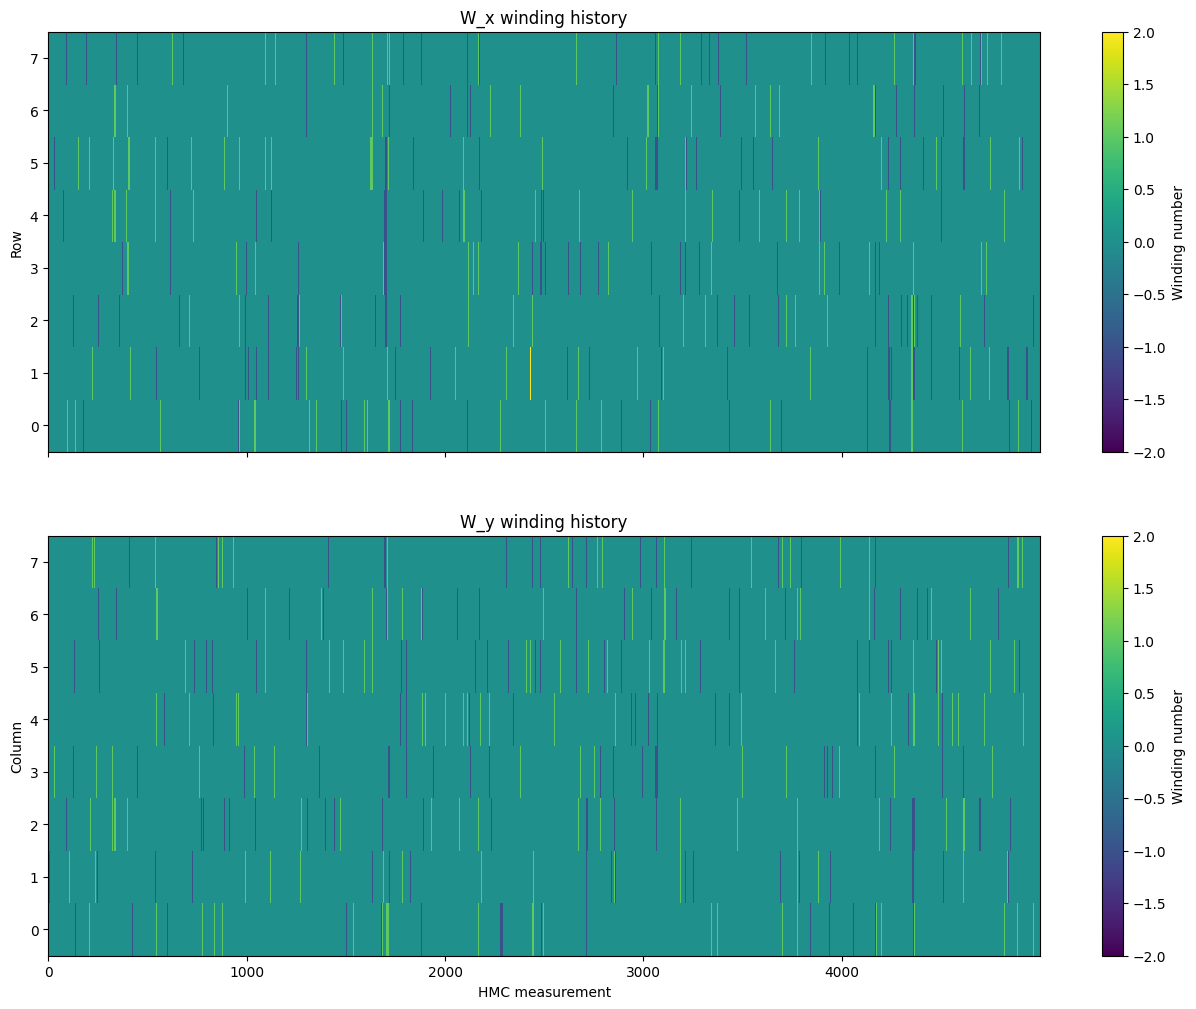

In [34]:
if RUN_LONG_EXPERIMENTS:
    W_x = grab(cold_run['winding_x'])
    W_y = grab(cold_run['winding_y'])

    fig, ax = plt.subplots(2, 1, figsize = (16, 12), sharex = True)

    im1 = ax[0].imshow(W_x.T, aspect = 'auto', interpolation = 'none', origin = 'lower', vmin = -2, vmax = 2)

    ax[0].set_ylabel('Row')
    ax[0].set_title('W_x winding history')
    fig.colorbar(im1, ax=ax[0], label='Winding number')


    im2 = ax[1].imshow(W_y.T, aspect = 'auto', interpolation = 'none', origin = 'lower', vmin = -2, vmax = 2)

    ax[1].set_xlabel('HMC measurement')
    ax[1].set_ylabel('Column')
    ax[1].set_title('W_y winding history')
    fig.colorbar(im2, ax=ax[1], label='Winding number')

    plt.show()

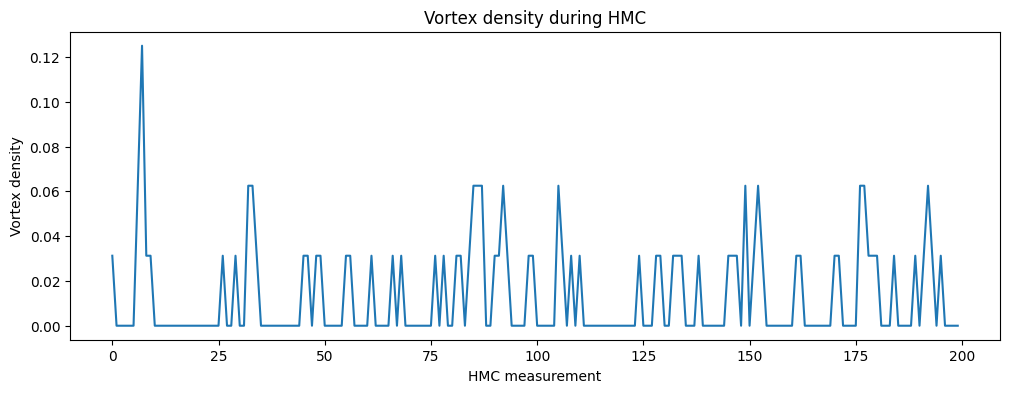

In [35]:
if RUN_LONG_EXPERIMENTS:
    n_plot = 200

    plt.figure(figsize=(12, 4))

    plt.plot(
        grab(cold_run['vortex_density'][:n_plot])
    )

    plt.xlabel('HMC measurement')
    plt.ylabel('Vortex density')
    plt.title('Vortex density during HMC')

    plt.show()

#### Calculate autocorrelation for energy

In [36]:
def autocorrelation(x, max_lag):
    """
    For a chosen measurable, this function measures the autocorrelation between samples for each HMC unit step form zeroth to max_lag
    """
    x = grab(x)
    if x.ndim != 1 or len(x) < 2 or not np.isfinite(x).all():
        raise ValueError("x must contain at least two finite scalar measurements")
    if isinstance(max_lag, bool) or not isinstance(max_lag, Integral) or not 0 <= max_lag < len(x):
        raise ValueError("max_lag must be an integer in [0, len(x))")
    if np.mean((x - x.mean())**2) == 0:
        raise ValueError("autocorrelation is undefined for a constant series")

    #subtract the mean
    x = x - x.mean()

    variance = np.mean(x**2)

    #stoe non-normalised autocorrelation values
    autocorr = [] 

    for lag in range(max_lag + 1):

        if lag == 0:
            autocorr.append(1.0)

        else:
            correlation = np.sum(x[:-lag] * x[lag:]) * 1/(len(x)) #Find biased cofiguration by always dividing by the total number of configurations
            autocorr.append(correlation / variance) #dividing by variance ensures that 1/N cancels out and the autocorr is bounded between -1 and 1

    return np.array(autocorr)

In [37]:
if RUN_LONG_EXPERIMENTS:
    energy_autocorr = autocorrelation(cold_run['energy_per_site'], max_lag=100)

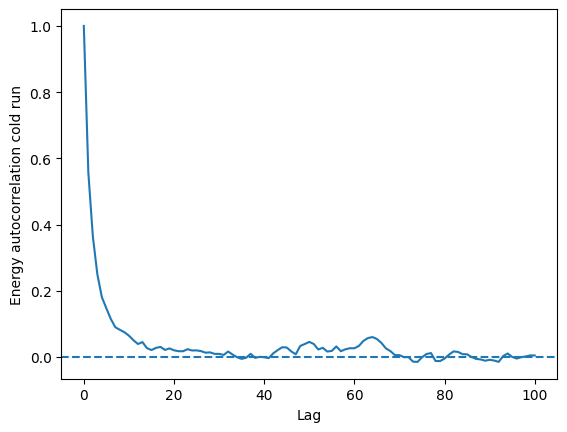

In [38]:
if RUN_LONG_EXPERIMENTS:
    im, ax = plt.subplots()

    plt.plot(np.arange(len(energy_autocorr)),energy_autocorr)

    plt.axhline(0, linestyle='--')

    plt.xlabel('Lag')
    plt.ylabel('Energy autocorrelation cold run')

    plt.show()

In [39]:
def integrated_autocorrelation_time(autocorr, c = 5):
    
    autocorr = np.asarray(autocorr)
    if autocorr.ndim != 1 or len(autocorr) == 0 or not np.isfinite(autocorr).all():
        raise ValueError("autocorr must be a nonempty finite 1D sequence")
    _finite_real("c", c, minimum=0, strict=True)

    #autocorrelation time has a initial value of 0.5, since for lag = 0, autocorr = 1. 
    autocorr_time = 0.5

    #record last lag before function breaks or calculation ends
    last_lag = 0
    
    for lag in range(1, len(autocorr)):
        
        autocorr_time += autocorr[lag]
        last_lag = lag 

        #truncate when the window size is bigger than the autocorrelation time multiplied by a heuristic constant
        if lag >= c * autocorr_time:
            break

    return autocorr_time, last_lag

In [40]:
def indipendent_samples_num(x, autocorr_time):
    """
    Measures the effective number of independent samples given the calculated
    integrated autocorrelation time.

    For example, if we measure 1000 values but N_eff = 200, then the 1000
    correlated measurements contain roughly the same statistical information
    as 200 independent measurements.

    THIS DOES NOT mean that there are literally 200 independent samples in
    the chain, e.g. one independent sample every 5 measurements.

    The input x should be the sequence of measured values of the observable,
    e.g. the energy measurements.
    """
    
    _finite_real("autocorr_time", autocorr_time, minimum=0, strict=True)
    if len(x) == 0:
        raise ValueError("x must contain measurements")

    #define the number of measured values
    N = len(x)
    
    #calculate the effective number of uncorrelated values given the autocorr time
    N_eff = N/(autocorr_time * 2)

    return N_eff

In [41]:
if RUN_LONG_EXPERIMENTS:
    autocorr_time, last_lag = integrated_autocorrelation_time(energy_autocorr)

    N_eff = indipendent_samples_num(cold_run['energy_per_site'], autocorr_time)

    print(f"Integrated autocorrelation time energy:{autocorr_time}")
    print(f"Last lag energy: {last_lag}")
    print(f"Effective number of independent energy samples:{round(N_eff)}")

Integrated autocorrelation time energy:2.558860756456852
Last lag energy: 13
Effective number of independent energy samples:977


#### Calculate autocorrelation for magnetisation 

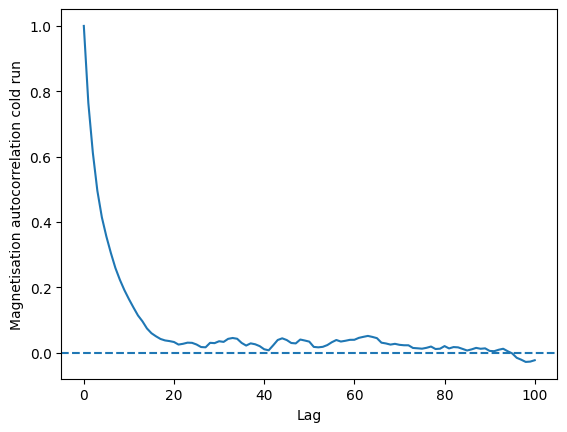

In [42]:
if RUN_LONG_EXPERIMENTS:
    magnetisation_autocorr = autocorrelation(cold_run['magnetisation'], max_lag=100)

    im, ax = plt.subplots()

    plt.plot(np.arange(len(magnetisation_autocorr)),magnetisation_autocorr)

    plt.axhline(0, linestyle='--')

    plt.xlabel('Lag')
    plt.ylabel('Magnetisation autocorrelation cold run')

    plt.show()

In [43]:
if RUN_LONG_EXPERIMENTS:
    autocorr_time, last_lag = integrated_autocorrelation_time(magnetisation_autocorr)

    N_eff = indipendent_samples_num(cold_run['magnetisation'], autocorr_time)

    print(f"Integrated autocorrelation time magnetisation:{autocorr_time}")
    print(f"Last lag magnetisation: {last_lag}")
    print(f"Effective number of independent magnetisation samples:{round(N_eff)}")

Integrated autocorrelation time magnetisation:5.116413075476885
Last lag magnetisation: 26
Effective number of independent magnetisation samples:489


#### Calculate autocorrelation for vortex density

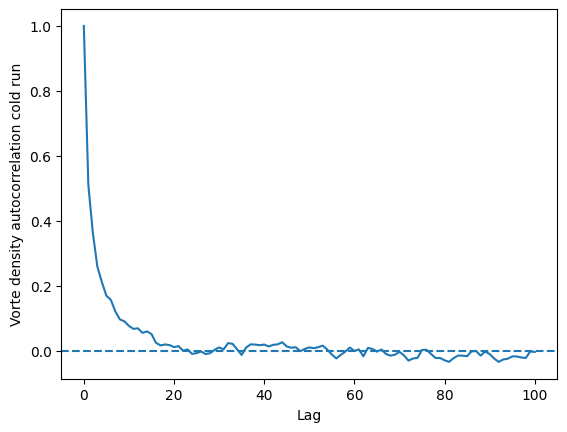

In [44]:
if RUN_LONG_EXPERIMENTS:
    v_density_autocorr = autocorrelation(cold_run['vortex_density'], max_lag=100)

    im, ax = plt.subplots()

    plt.plot(np.arange(len(v_density_autocorr)),v_density_autocorr)

    plt.axhline(0, linestyle='--')

    plt.xlabel('Lag')
    plt.ylabel('Vorte density autocorrelation cold run')

    plt.show()

In [45]:
if RUN_LONG_EXPERIMENTS:
    autocorr_time, last_lag = integrated_autocorrelation_time(v_density_autocorr)

    N_eff = indipendent_samples_num(cold_run['vortex_density'], autocorr_time)

    print(f"Integrated autocorrelation time vortex density:{autocorr_time}")
    print(f"Last lag vortex density: {last_lag}")
    print(f"Effective number of independent vortex density samples:{round(N_eff)}")

Integrated autocorrelation time vortex density:2.8705319836735725
Last lag vortex density: 15
Effective number of independent vortex density samples:871


#### Compare helicity modulus for the hot and cold runs at beta = 1
#### Since both runs sample the same equilibrium distribution, the helicity modulus should agree after sufficient thermalisation.

In [46]:
if RUN_LONG_EXPERIMENTS:
    Y_cold, Y_x_cold, Y_y_cold = helicity_modulus(cold_run, action, L = 8)
    Y_hot, Y_x_hot, Y_y_hot = helicity_modulus(hot_run, action, L = 8)

    print(f"Helicity modulus cold run: {Y_cold.item():.4f}")
    print(f"Helicity modulus hot run: {Y_hot.item():.4f}")

    print(f"Helicity modulus x cold run: {Y_x_cold.item():.4f}")
    print(f"Helicity modulus y cold run: {Y_y_cold.item():.4f}")

    print(f"Helicity modulus x hot run: {Y_x_hot.item():.4f}")
    print(f"Helicity modulus y hot run: {Y_y_hot.item():.4f}")

Helicity modulus cold run: 0.5776
Helicity modulus hot run: 0.5679
Helicity modulus x cold run: 0.5707
Helicity modulus y cold run: 0.5846
Helicity modulus x hot run: 0.5605
Helicity modulus y hot run: 0.5753


# L=8 Experiment

### Vary beta across the BKT region, for J = 1, beta_BKT is approximately 1.12 in the infinite-volume limit. At finite L we expect a smooth crossover rather than a sharp transition.

In [47]:
if RUN_LONG_EXPERIMENTS:
    beta_values = [0.7, 0.9, 1.0, 1.1, 1.2, 1.4]

    L_experiment = 8

    n_therm_experiment = 1500
    n_iter_experiment = 5000

    dt_experiment = 0.05
    n_leap_experiment = 20

    max_lag_experiment = 500

    #store the full HMC runs in case we want to analyse individual beta values later
    beta_runs = {}

    #store useful quantities for every beta value
    experiment_results = []

#### Run HMC for each value of beta and calculate the physical observables and their autocorrelation times

In [48]:
if RUN_LONG_EXPERIMENTS:
    set_seed(SEED + 3)

    for beta in beta_values:

        print(f"\nRunning beta = {beta}")

        #define the action for the chosen beta value
        action_beta = XY_Action(J = 1.0, beta = beta)

        #run HMC
        run = run_hmc(action_beta, L = L_experiment, start = 'hot', n_therm = n_therm_experiment, n_iter = n_iter_experiment, dt = dt_experiment,
                       n_leap = n_leap_experiment, n_meas = 1)

        #store the entire run
        beta_runs[beta] = run


        #ENERGY

        energy = run['energy_per_site']

        energy_autocorr = autocorrelation(energy, max_lag = max_lag_experiment)

        tau_energy, last_lag_energy = integrated_autocorrelation_time(energy_autocorr)

        N_eff_energy = indipendent_samples_num(energy, tau_energy)

        mean_energy = energy.mean().item()

        #calculate an approximate error on the mean of independent samples, so use the effective number of samples instead of all samples. 
        error_energy = energy.std().item() / np.sqrt(N_eff_energy)


        #MAGNETISATION

        magnetisation = run['magnetisation']

        magnetisation_autocorr = autocorrelation(magnetisation, max_lag = max_lag_experiment)

        tau_magnetisation, last_lag_magnetisation = integrated_autocorrelation_time(magnetisation_autocorr)

        N_eff_magnetisation = indipendent_samples_num(magnetisation, tau_magnetisation)

        mean_magnetisation = magnetisation.mean().item()

        error_magnetisation = magnetisation.std().item() / np.sqrt(N_eff_magnetisation)


        #VORTEX DENSITY

        v_density = run['vortex_density']

        vortex_autocorr = autocorrelation(v_density, max_lag = max_lag_experiment)

        tau_vortex, last_lag_vortex = integrated_autocorrelation_time(vortex_autocorr)

        N_eff_vortex = indipendent_samples_num(v_density, tau_vortex)

        mean_vortex_density = v_density.mean().item()

        error_vortex_density = v_density.std().item() / np.sqrt(N_eff_vortex)


        #WINDING

        W_x = run['winding_x']
        W_y = run['winding_y']

        #calculate the fraction of all measured loops which have non-zero winding
        nonzero_winding_x = (torch.abs(W_x) > 0).float().mean().item()
        nonzero_winding_y = (torch.abs(W_y) > 0).float().mean().item()


        #STORE RESULTS

        experiment_results.append({
            'beta': beta,

            'energy': mean_energy,
            'energy_error': error_energy,
            'tau_energy': tau_energy,
            'N_eff_energy': N_eff_energy,

            'magnetisation': mean_magnetisation,
            'magnetisation_error': error_magnetisation,
            'tau_magnetisation': tau_magnetisation,
            'N_eff_magnetisation': N_eff_magnetisation,

            'vortex_density': mean_vortex_density,
            'vortex_density_error': error_vortex_density,
            'tau_vortex': tau_vortex,
            'N_eff_vortex': N_eff_vortex,

            'nonzero_winding_x': nonzero_winding_x,
            'nonzero_winding_y': nonzero_winding_y,

            'acceptance_rate': run['acceptance_rate']
        })


        #print the main results immediately after every run

        print(f"Acceptance rate: {run['acceptance_rate']:.3f}")

        print(f"Energy per site: {mean_energy:.4f} +/- {error_energy:.4f}, tau = {tau_energy:.2f}")

        print(f"Magnetisation: {mean_magnetisation:.4f} +/- {error_magnetisation:.4f}, tau = {tau_magnetisation:.2f}")

        print(f"Vortex density: {mean_vortex_density:.4f} +/- {error_vortex_density:.4f}, tau = {tau_vortex:.2f}")


Running beta = 0.7


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.998
Energy per site: -0.8490 +/- 0.0074, tau = 4.74
Magnetisation: 0.3846 +/- 0.0094, tau = 8.63
Vortex density: 0.1193 +/- 0.0023, tau = 4.14

Running beta = 0.9


...

Acceptance rate: 0.995
Energy per site: -1.5131 +/- 0.0025, tau = 1.76
Magnetisation: 0.8036 +/- 0.0017, tau = 2.36
Vortex density: 0.0040 +/- 0.0003, tau = 1.88

Running beta = 1.4


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.995
Energy per site: -1.5928 +/- 0.0020, tau = 1.79
Magnetisation: 0.8370 +/- 0.0011, tau = 1.51
Vortex density: 0.0010 +/- 0.0001, tau = 1.12


#### Extract the measured quantities from the experiment so that they can easily be plotted against beta

In [49]:
if RUN_LONG_EXPERIMENTS:
    betas = np.array([result['beta'] for result in experiment_results])

    mean_energy = np.array([result['energy'] for result in experiment_results])

    error_energy = np.array([result['energy_error'] for result in experiment_results])

    mean_magnetisation = np.array([result['magnetisation'] for result in experiment_results])

    error_magnetisation = np.array([result['magnetisation_error'] for result in experiment_results])

    mean_vortex_density = np.array([result['vortex_density'] for result in experiment_results])

    error_vortex_density = np.array([result['vortex_density_error'] for result in experiment_results])

    tau_energy = np.array([result['tau_energy'] for result in experiment_results])

    tau_magnetisation = np.array([result['tau_magnetisation'] for result in experiment_results])

    tau_vortex = np.array([result['tau_vortex'] for result in experiment_results])

    acceptance_rate = np.array([result['acceptance_rate'] for result in experiment_results])

    nonzero_winding_x = np.array([result['nonzero_winding_x'] for result in experiment_results])

    nonzero_winding_y = np.array([result['nonzero_winding_y'] for result in experiment_results])

#### Plot the physical quantities as beta changes

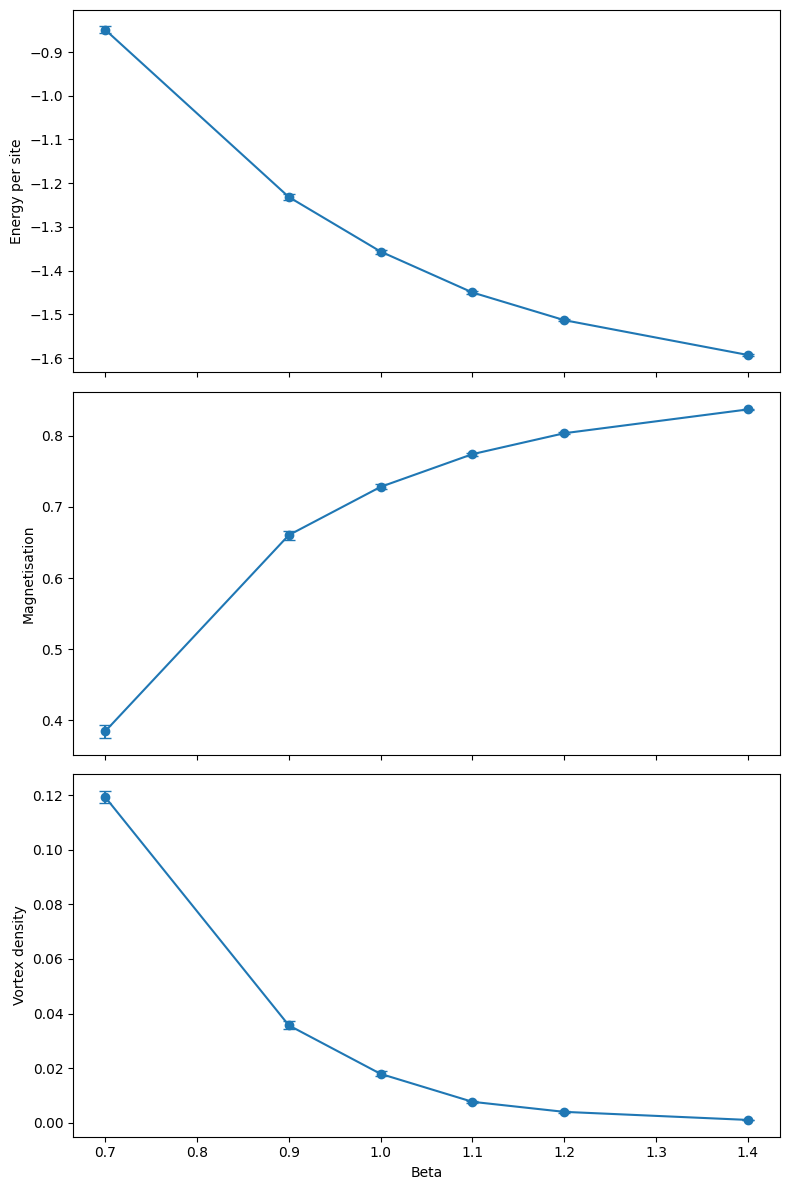

In [50]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots(3, 1, figsize = (8, 12), sharex = True)

    #energy per site
    ax[0].errorbar(betas, mean_energy, yerr = error_energy, marker = 'o', capsize = 4)

    ax[0].set_ylabel('Energy per site')


    #magnetisation
    ax[1].errorbar(betas, mean_magnetisation, yerr = error_magnetisation, marker = 'o', capsize = 4)

    ax[1].set_ylabel('Magnetisation')


    #vortex density
    ax[2].errorbar(betas, mean_vortex_density, yerr = error_vortex_density, marker = 'o', capsize = 4)

    ax[2].set_xlabel('Beta')
    ax[2].set_ylabel('Vortex density')

    plt.tight_layout()

    plt.show()

#### Compare the integrated autocorrelation time of the different physical observables.
#### A larger autocorrelation time means that HMC is producing more strongly correlated measurements for that observable.

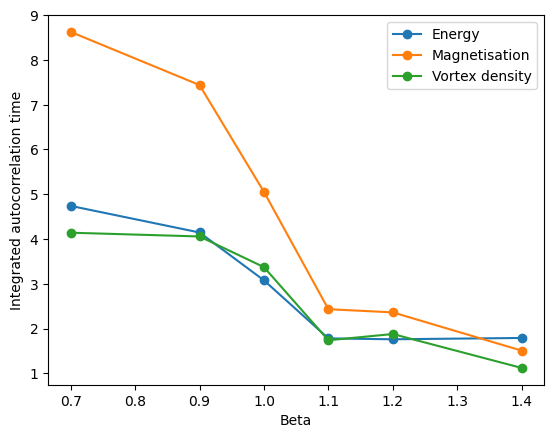

In [51]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(betas, tau_energy, marker = 'o', label = 'Energy')

    plt.plot(betas, tau_magnetisation, marker = 'o', label = 'Magnetisation')

    plt.plot(betas, tau_vortex, marker = 'o', label = 'Vortex density')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time')

    plt.legend()

    plt.show()

#### Check the HMC acceptance rate for every beta value.
#### This is important since if the acceptance rate changes substantially, the change in autocorrelation could simply be due to poor HMC tuning rather than the physics becoming more difficult to sample.

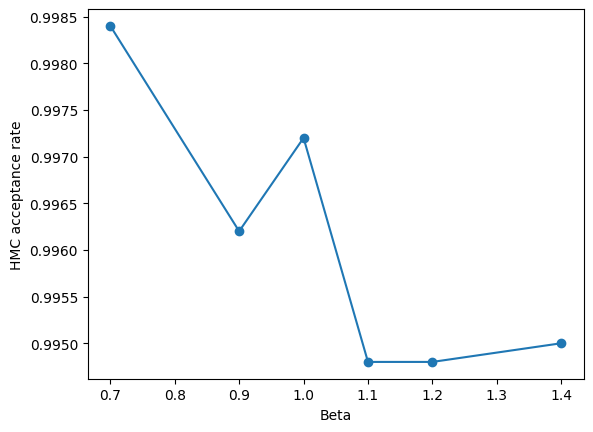

In [52]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(betas, acceptance_rate, marker = 'o')

    plt.xlabel('Beta')
    plt.ylabel('HMC acceptance rate')

    plt.show()

#### Plot the fraction of rows and columns with non-zero winding as beta changes.
#### This is only used as a simple diagnostic of winding activity and doesn't directly define the global topological sector.

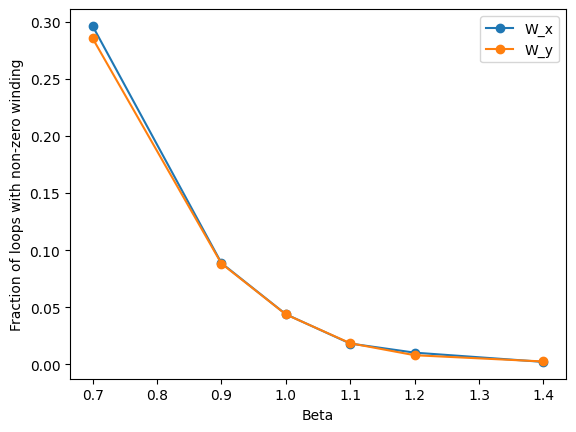

In [53]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    plt.plot(betas, nonzero_winding_x, marker = 'o', label = 'W_x')

    plt.plot(betas, nonzero_winding_y, marker = 'o', label = 'W_y')

    plt.xlabel('Beta')
    plt.ylabel('Fraction of loops with non-zero winding')

    plt.legend()

    plt.show()

#### Look directly at the winding history for individual beta values to see how frequently HMC changes winding configurations

In [54]:
def plot_winding_history(run, beta, n_plot = 1000):

    W_x = grab(run['winding_x'][:n_plot])
    W_y = grab(run['winding_y'][:n_plot])

    fig, ax = plt.subplots(2, 1, figsize = (14, 7), sharex = True)

    im1 = ax[0].imshow(W_x.T, aspect = 'auto', interpolation = 'none', origin = 'lower', vmin = -2, vmax = 2)

    ax[0].set_ylabel('Row')
    ax[0].set_title(f'W_x winding history, beta = {beta}')

    fig.colorbar(im1, ax = ax[0], label = 'Winding number')


    im2 = ax[1].imshow(W_y.T, aspect = 'auto', interpolation = 'none', origin = 'lower', vmin = -2, vmax = 2)

    ax[1].set_xlabel('HMC measurement')
    ax[1].set_ylabel('Column')
    ax[1].set_title(f'W_y winding history, beta = {beta}')

    fig.colorbar(im2, ax = ax[1], label = 'Winding number')

    plt.tight_layout()

    plt.show()

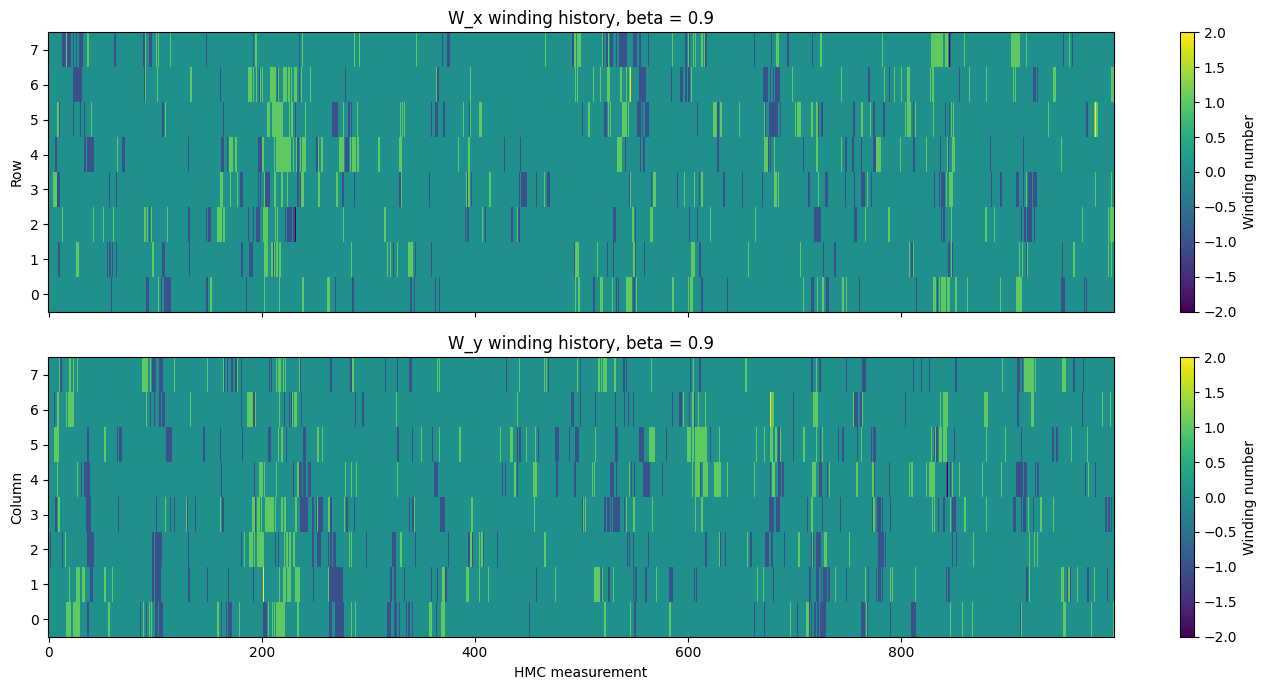

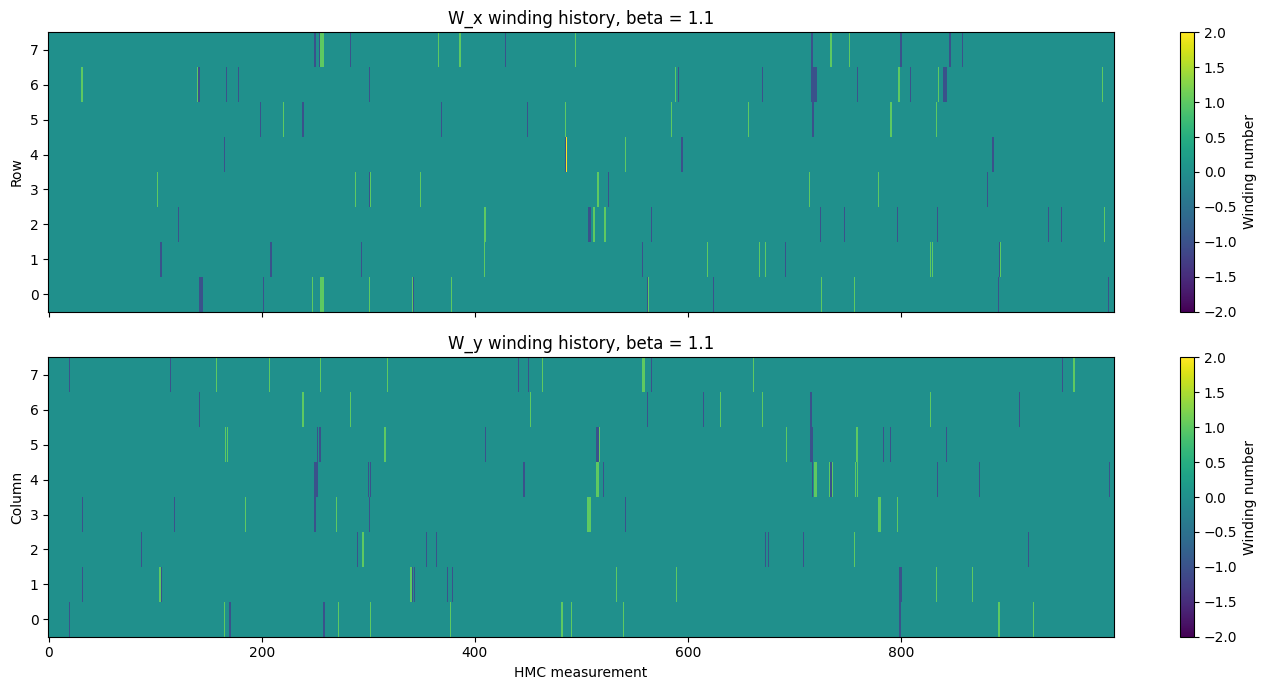

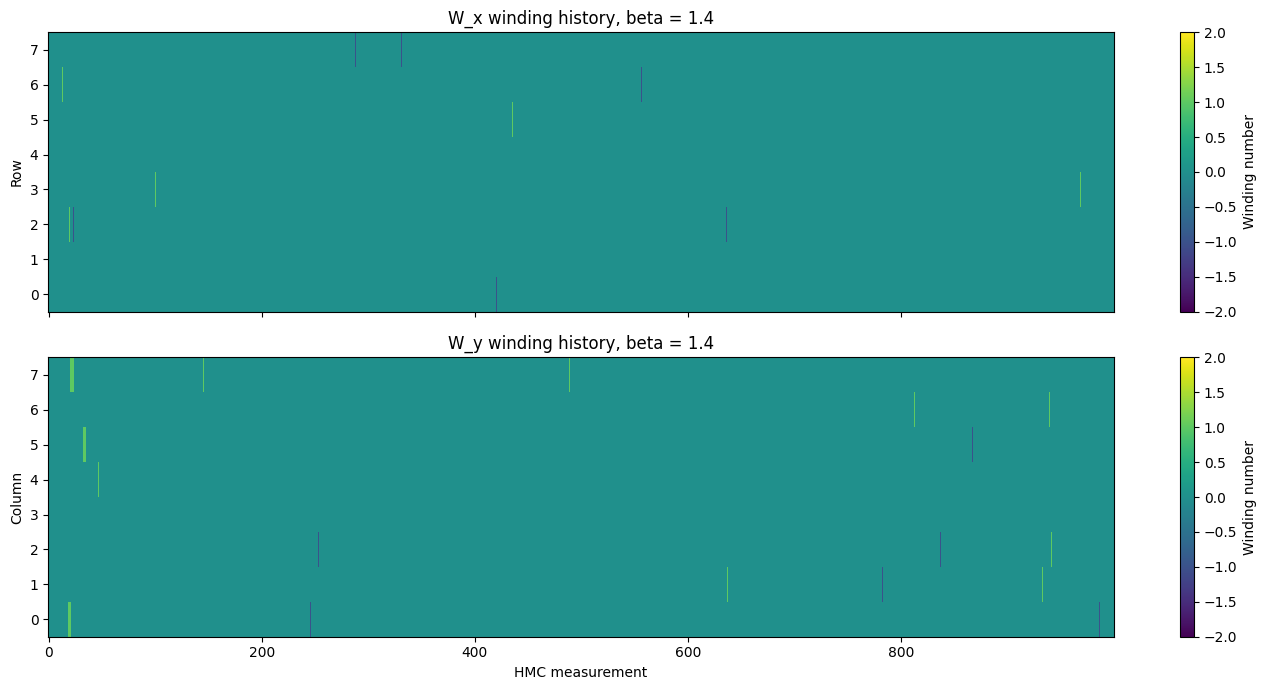

In [55]:
if RUN_LONG_EXPERIMENTS:
    plot_winding_history(beta_runs[0.9], beta = 0.9)

    plot_winding_history(beta_runs[1.1], beta = 1.1)

    plot_winding_history(beta_runs[1.4], beta = 1.4)

# Finite-sized experiment including helicity modulus

#### Repeat the experiment, but focus on beta values closer to BKT and bigger lattice

In [56]:
if RUN_LONG_EXPERIMENTS:
    L_values = [8, 16]

    beta_values_finite_size = [0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2]

    n_therm_experiment = 1500
    n_iter_experiment = 5000

    dt_experiment = 0.05
    n_leap_experiment = 20

    max_lag_experiment = 500

    #store full runs for each lattice size and beta
    finite_size_runs = {}

    #store summary results
    finite_size_results = []

#### Run the same beta experiment for each lattice size

In [57]:
if RUN_LONG_EXPERIMENTS:
    set_seed(SEED + 4)

    for L in L_values:

        #create a dictionary containing the full runs for each beta at this lattice size
        finite_size_runs[L] = {}

        print(f"\nStarting L = {L}")


        for beta in beta_values_finite_size:

            print(f"\nRunning L = {L}, beta = {beta}")

            action_beta = XY_Action(J = 1.0, beta = beta)

            run = run_hmc(action_beta, L = L, start = 'hot', n_therm = n_therm_experiment, n_iter = n_iter_experiment, dt = dt_experiment,
                           n_leap = n_leap_experiment, n_meas = 1)

            #store full simulation
            finite_size_runs[L][beta] = run


            #ENERGY

            energy = run['energy_per_site']

            energy_autocorr = autocorrelation(energy, max_lag = max_lag_experiment)

            tau_energy, last_lag_energy = integrated_autocorrelation_time(energy_autocorr)

            N_eff_energy = indipendent_samples_num(energy, tau_energy)

            mean_energy = energy.mean().item()

            error_energy = energy.std().item() / np.sqrt(N_eff_energy)


            #MAGNETISATION

            magnetisation = run['magnetisation']

            magnetisation_autocorr = autocorrelation(magnetisation, max_lag = max_lag_experiment)

            tau_magnetisation, last_lag_magnetisation = integrated_autocorrelation_time(magnetisation_autocorr)

            N_eff_magnetisation = indipendent_samples_num(magnetisation, tau_magnetisation)

            mean_magnetisation = magnetisation.mean().item()

            error_magnetisation = magnetisation.std().item() / np.sqrt(N_eff_magnetisation)


            #VORTEX DENSITY

            v_density = run['vortex_density']

            vortex_autocorr = autocorrelation(v_density, max_lag = max_lag_experiment)

            tau_vortex, last_lag_vortex = integrated_autocorrelation_time(vortex_autocorr)

            N_eff_vortex = indipendent_samples_num(v_density, tau_vortex)

            mean_vortex_density = v_density.mean().item()

            error_vortex_density = v_density.std().item() / np.sqrt(N_eff_vortex)


            #WINDING

            W_x = run['winding_x']
            W_y = run['winding_y']

            nonzero_winding_x = (torch.abs(W_x) > 0).float().mean().item()
            nonzero_winding_y = (torch.abs(W_y) > 0).float().mean().item()

    
            #HELICITY MODULUS

            Y, Y_x, Y_y = helicity_modulus(run, action_beta, L = L)

            helicity = Y.item()
            helicity_x = Y_x.item()
            helicity_y = Y_y.item()

   
            #STORE RESULTS

            finite_size_results.append({
                'L': L,
                'beta': beta,

                'energy': mean_energy,
                'energy_error': error_energy,
                'tau_energy': tau_energy,
                'N_eff_energy': N_eff_energy,

                'magnetisation': mean_magnetisation,
                'magnetisation_error': error_magnetisation,
                'tau_magnetisation': tau_magnetisation,
                'N_eff_magnetisation': N_eff_magnetisation,

                'vortex_density': mean_vortex_density,
                'vortex_density_error': error_vortex_density,
                'tau_vortex': tau_vortex,
                'N_eff_vortex': N_eff_vortex,

                'nonzero_winding_x': nonzero_winding_x,
                'nonzero_winding_y': nonzero_winding_y,

                'helicity': helicity,
                'helicity_x': helicity_x,
                'helicity_y': helicity_y,

                'acceptance_rate': run['acceptance_rate']
            })


            print(f"Acceptance rate: {run['acceptance_rate']:.3f}")
            print(f"Energy per site: {mean_energy:.4f} +/- {error_energy:.4f}, tau = {tau_energy:.2f}")
            print(f"Magnetisation: {mean_magnetisation:.4f} +/- {error_magnetisation:.4f}, tau = {tau_magnetisation:.2f}")
            print(f"Vortex density: {mean_vortex_density:.4f} +/- {error_vortex_density:.4f}, tau = {tau_vortex:.2f}")
            print(f"Helicity modulus: {helicity:.4f}, Y_x = {helicity_x:.4f}, Y_y = {helicity_y:.4f}")


Starting L = 8

Running L = 8, beta = 0.85


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.996
Energy per site: -1.1337 +/- 0.0091, tau = 6.88
Magnetisation: 0.5896 +/- 0.0102, tau = 12.43
Vortex density: 0.0539 +/- 0.0024, tau = 6.80
Helicity modulus: 0.3264, Y_x = 0.3380, Y_y = 0.3148

Running L = 8, beta = 0.9


...

Acceptance rate: 0.989
Energy per site: -1.4736 +/- 0.0015, tau = 2.09
Magnetisation: 0.7346 +/- 0.0023, tau = 5.83
Vortex density: 0.0060 +/- 0.0002, tau = 1.88
Helicity modulus: 0.6737, Y_x = 0.6743, Y_y = 0.6731

Running L = 16, beta = 1.2


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.987
Energy per site: -1.5020 +/- 0.0014, tau = 2.06
Magnetisation: 0.7498 +/- 0.0025, tau = 7.60
Vortex density: 0.0043 +/- 0.0002, tau = 1.86
Helicity modulus: 0.6971, Y_x = 0.6919, Y_y = 0.7024


#### Plot the integrated autocorrelation time against beta for each lattice size.
#### If critical slowing down becomes stronger as the lattice grows, we expect the autocorrelation peak to become larger and possibly move as finite-size effects decrease.

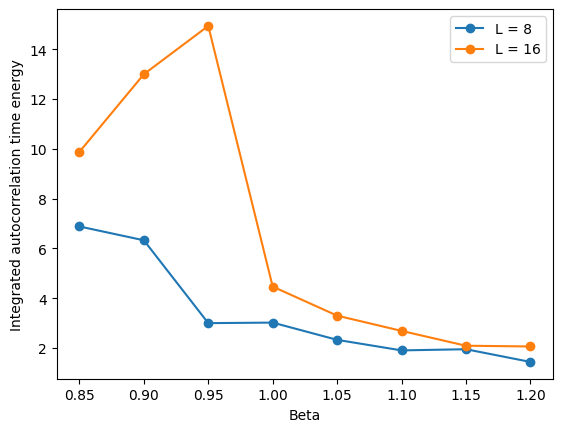

In [58]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_energy_L = np.array([result['tau_energy'] for result in results_L])

        plt.plot(betas_L, tau_energy_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time energy')

    plt.legend()

    plt.show()

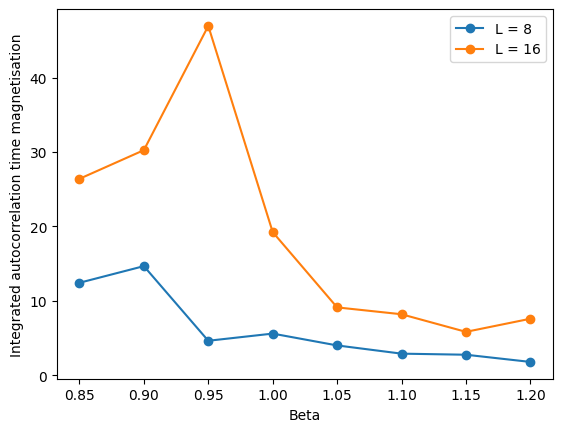

In [59]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_magnetisation_L = np.array([result['tau_magnetisation'] for result in results_L])

        plt.plot(betas_L, tau_magnetisation_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time magnetisation')

    plt.legend()

    plt.show()

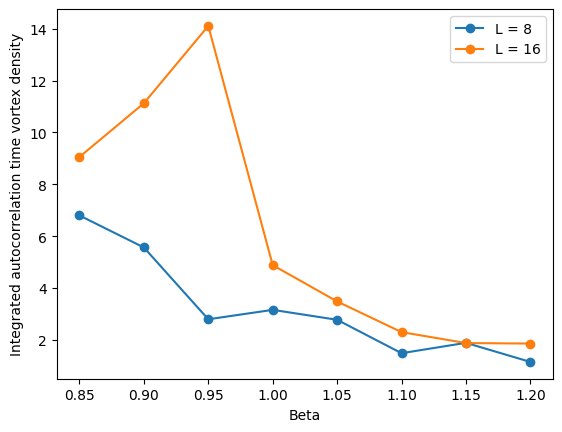

In [60]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_vortex_L = np.array([result['tau_vortex'] for result in results_L])

        plt.plot(betas_L, tau_vortex_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time vortex density')

    plt.legend()

    plt.show()

#### Plot the helicity modulus against beta for each lattice size and compare it to the universal BKT jump condition Y = 2/(pi*beta).

#### Compare the physical observables for different lattice sizes.
#### Magnetisation is particularly interesting because in the 2D XY model there is no true spontaneous magnetisation in the thermodynamic limit, so its finite-size behaviour should change as L increases.

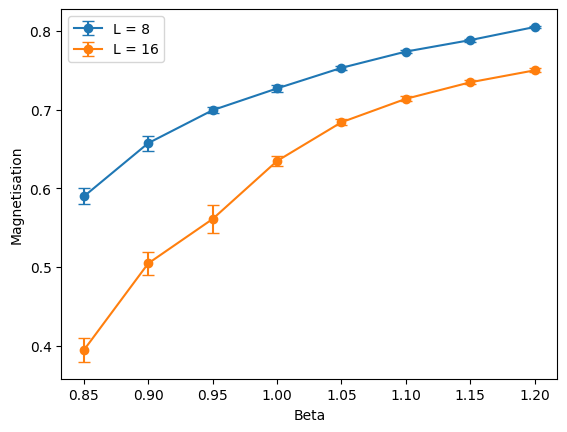

In [61]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        magnetisation_L = np.array([result['magnetisation'] for result in results_L])
        error_magnetisation_L = np.array([result['magnetisation_error'] for result in results_L])

        plt.errorbar(betas_L, magnetisation_L, yerr = error_magnetisation_L, marker = 'o', capsize = 4, label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Magnetisation')

    plt.legend()

    plt.show()

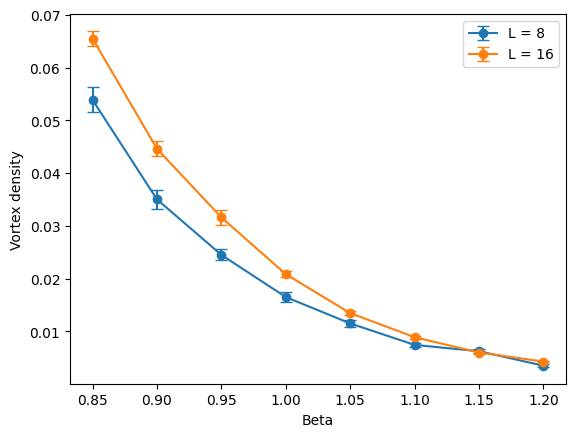

In [62]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        vortex_density_L = np.array([result['vortex_density'] for result in results_L])
        error_vortex_density_L = np.array([result['vortex_density_error'] for result in results_L])

        plt.errorbar(betas_L, vortex_density_L, yerr = error_vortex_density_L, marker = 'o', capsize = 4, label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Vortex density')

    plt.legend()

    plt.show()

#### Plot the helicity modulus against beta for each lattice size and compare it to the universal BKT jump condition Y = 2/(pi*beta)

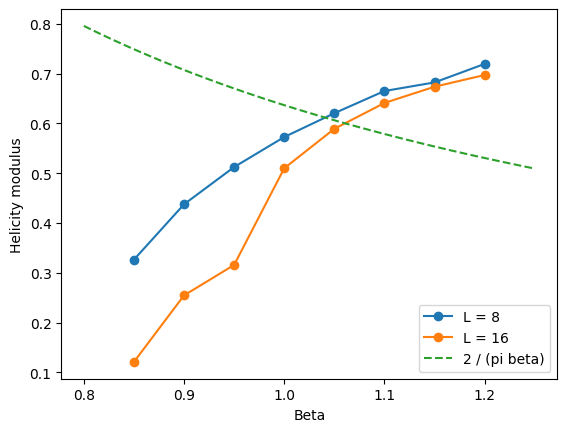

In [63]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]
    
        betas_L = np.array([result['beta'] for result in results_L])
        helicity_L = np.array([result['helicity'] for result in results_L])

        plt.plot(betas_L, helicity_L, marker = 'o', label = f'L = {L}')

    #plot the universal BKT jump condition
    beta_jump = np.linspace(0.8, 1.25, 200)

    plt.plot(beta_jump, 2 / (np.pi * beta_jump), '--', label = '2 / (pi beta)')

    plt.xlabel('Beta')
    plt.ylabel('Helicity modulus')

    plt.legend()

    plt.show()

#### Check that the helicity modulus in the x and y directions stays approximately equal as expected from isotropy.

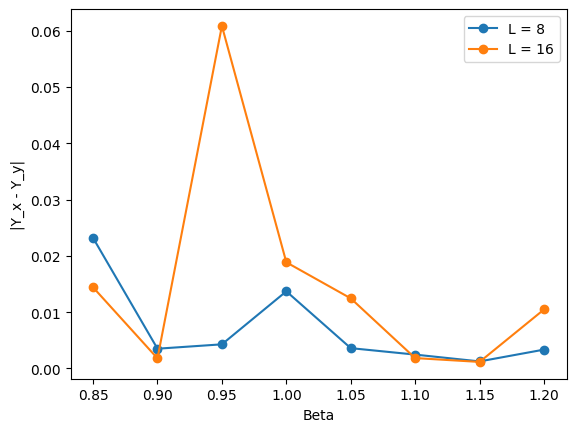

In [64]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
    
        helicity_x_L = np.array([result['helicity_x'] for result in results_L])
        helicity_y_L = np.array([result['helicity_y'] for result in results_L])

        helicity_difference = np.abs(helicity_x_L - helicity_y_L)

        plt.plot(betas_L, helicity_difference, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('|Y_x - Y_y|')

    plt.legend()

    plt.show()

#### Verify that any change in autocorrelation isn't simply caused by the HMC acceptance rate becoming significantly worse at larger lattice sizes

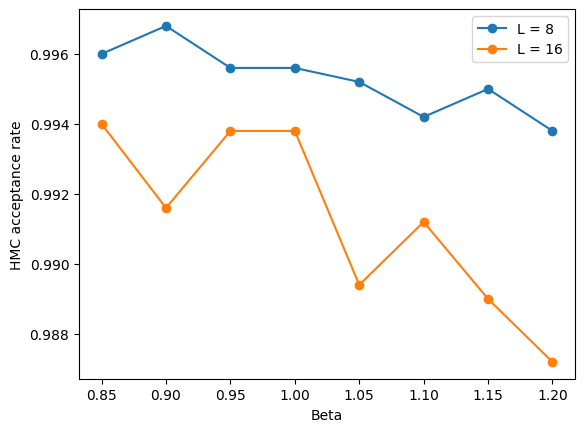

In [65]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        acceptance_L = np.array([result['acceptance_rate'] for result in results_L])

        plt.plot(betas_L, acceptance_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('HMC acceptance rate')

    plt.legend()

    plt.show()

# Run the same experiment for L = 32 and merge the plots

### Focus on the beta range where the autocorrelation peak is developing

In [66]:
if RUN_LONG_EXPERIMENTS:
    L = 32

    beta_values_L32 = [0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.15]

    n_therm_L32 = 1500
    n_iter_L32 = 5000

    dt_L32 = 0.05
    n_leap_L32 = 20

    max_lag_L32 = 500

    #create a dictionary to store the full L = 32 runs
    finite_size_runs[32] = {}

#### Run HMC for L = 32 and append the results to the existing finite-size results

In [67]:
if RUN_LONG_EXPERIMENTS:
    set_seed(SEED + 5)

    for beta in beta_values_L32:

        print(f"\nRunning L = {L}, beta = {beta}")

        action_beta = XY_Action(J = 1.0, beta = beta)

        run = run_hmc(action_beta, L = L, start = 'hot', n_therm = n_therm_L32, n_iter = n_iter_L32, dt = dt_L32, n_leap = n_leap_L32, n_meas = 1)

        #store the full simulation
        finite_size_runs[L][beta] = run


        #ENERGY

        energy = run['energy_per_site']

        energy_autocorr = autocorrelation(energy, max_lag = max_lag_L32)

        tau_energy, last_lag_energy = integrated_autocorrelation_time(energy_autocorr)

        N_eff_energy = indipendent_samples_num(energy, tau_energy)

        mean_energy = energy.mean().item()

        error_energy = energy.std().item() / np.sqrt(N_eff_energy)


        #MAGNETISATION

        magnetisation = run['magnetisation']

        magnetisation_autocorr = autocorrelation(magnetisation, max_lag = max_lag_L32)

        tau_magnetisation, last_lag_magnetisation = integrated_autocorrelation_time(magnetisation_autocorr)

        N_eff_magnetisation = indipendent_samples_num(magnetisation, tau_magnetisation)

        mean_magnetisation = magnetisation.mean().item()

        error_magnetisation = magnetisation.std().item() / np.sqrt(N_eff_magnetisation)


        #VORTEX DENSITY

        v_density = run['vortex_density']

        vortex_autocorr = autocorrelation(v_density, max_lag = max_lag_L32)

        tau_vortex, last_lag_vortex = integrated_autocorrelation_time(vortex_autocorr)

        N_eff_vortex = indipendent_samples_num(v_density, tau_vortex)

        mean_vortex_density = v_density.mean().item()

        error_vortex_density = v_density.std().item() / np.sqrt(N_eff_vortex)


        #WINDING

        W_x = run['winding_x']
        W_y = run['winding_y']

        nonzero_winding_x = (torch.abs(W_x) > 0).float().mean().item()
        nonzero_winding_y = (torch.abs(W_y) > 0).float().mean().item()

        #HELICITY MODULUS

        Y, Y_x, Y_y = helicity_modulus(run, action_beta, L = L)

        helicity = Y.item()
        helicity_x = Y_x.item()
        helicity_y = Y_y.item()


        #STORE RESULTS

        finite_size_results.append({
            'L': L,
            'beta': beta,

            'energy': mean_energy,
            'energy_error': error_energy,
            'tau_energy': tau_energy,
            'N_eff_energy': N_eff_energy,

            'magnetisation': mean_magnetisation,
            'magnetisation_error': error_magnetisation,
            'tau_magnetisation': tau_magnetisation,
            'N_eff_magnetisation': N_eff_magnetisation,

            'vortex_density': mean_vortex_density,
            'vortex_density_error': error_vortex_density,
            'tau_vortex': tau_vortex,
            'N_eff_vortex': N_eff_vortex,

            'nonzero_winding_x': nonzero_winding_x,
            'nonzero_winding_y': nonzero_winding_y,

            'helicity': helicity,
            'helicity_x': helicity_x,
            'helicity_y': helicity_y,


            'acceptance_rate': run['acceptance_rate']
        })


        print(f"Acceptance rate: {run['acceptance_rate']:.3f}")
        print(f"Energy per site: {mean_energy:.4f} +/- {error_energy:.4f}, tau = {tau_energy:.2f}, N_eff = {round(N_eff_energy)}")
        print(f"Magnetisation: {mean_magnetisation:.4f} +/- {error_magnetisation:.4f}, tau = {tau_magnetisation:.2f}, N_eff = {round(N_eff_magnetisation)}")
        print(f"Vortex density: {mean_vortex_density:.4f} +/- {error_vortex_density:.4f}, tau = {tau_vortex:.2f}, N_eff = {round(N_eff_vortex)}")
        print(f"Helicity modulus: {helicity:.4f}, Y_x = {helicity_x:.4f}, Y_y = {helicity_y:.4f}")


Running L = 32, beta = 0.85


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.988
Energy per site: -1.0746 +/- 0.0021, tau = 6.94, N_eff = 360
Magnetisation: 0.2045 +/- 0.0179, tau = 86.60, N_eff = 29
Vortex density: 0.0691 +/- 0.0006, tau = 6.38, N_eff = 392
Helicity modulus: 0.0265, Y_x = 0.0516, Y_y = 0.0013

Running L = 32, beta = 0.9


...

Acceptance rate: 0.981
Energy per site: -1.4307 +/- 0.0010, tau = 3.34, N_eff = 748
Magnetisation: 0.6520 +/- 0.0056, tau = 31.94, N_eff = 78
Vortex density: 0.0098 +/- 0.0002, tau = 3.39, N_eff = 736
Helicity modulus: 0.6197, Y_x = 0.6227, Y_y = 0.6168

Running L = 32, beta = 1.15


  0%|          | 0/1500 [00:00<?, ?it/s]

Thermalisation loop completed...


  0%|          | 0/5000 [00:00<?, ?it/s]

Acceptance rate: 0.982
Energy per site: -1.4689 +/- 0.0008, tau = 2.08, N_eff = 1201
Magnetisation: 0.6863 +/- 0.0032, tau = 18.12, N_eff = 138
Vortex density: 0.0065 +/- 0.0001, tau = 2.32, N_eff = 1078
Helicity modulus: 0.6627, Y_x = 0.6631, Y_y = 0.6622


## Compare L = 8, 16 and 32

#### Plot the results from all three lattice sizes together. The L = 32 experiment doesn't need to have exactly the same beta range as the previous experiments.

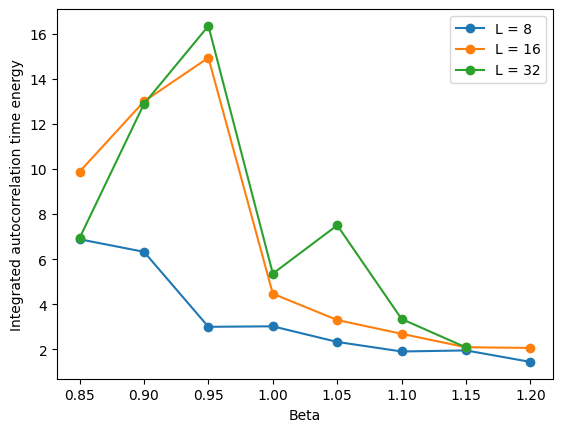

In [68]:
if RUN_LONG_EXPERIMENTS:
    L_values_plot = [8, 16, 32]

    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_energy_L = np.array([result['tau_energy'] for result in results_L])

        plt.plot(betas_L, tau_energy_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time energy')

    plt.legend()

    plt.show()

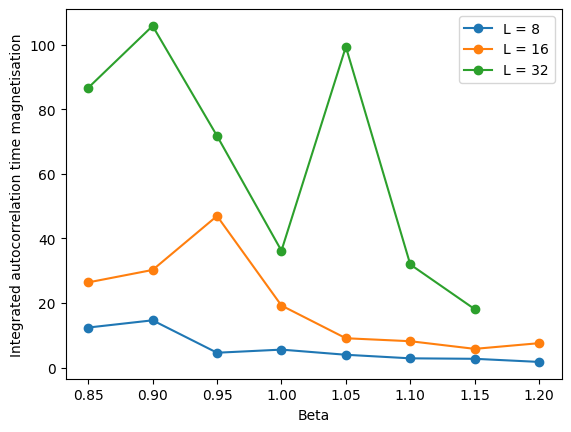

In [69]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_magnetisation_L = np.array([result['tau_magnetisation'] for result in results_L])

        plt.plot(betas_L, tau_magnetisation_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time magnetisation')

    plt.legend()

    plt.show()

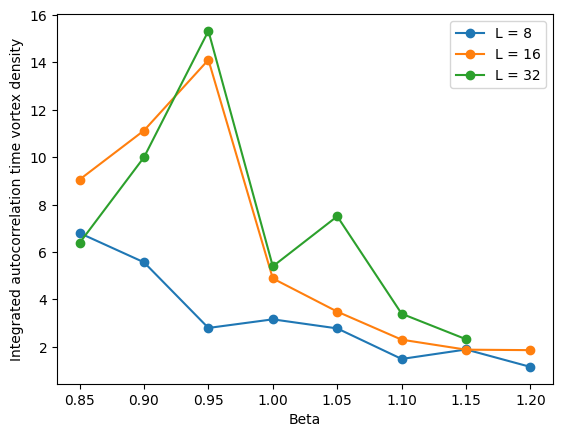

In [70]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        tau_vortex_L = np.array([result['tau_vortex'] for result in results_L])

        plt.plot(betas_L, tau_vortex_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('Integrated autocorrelation time vortex density')

    plt.legend()

    plt.show()

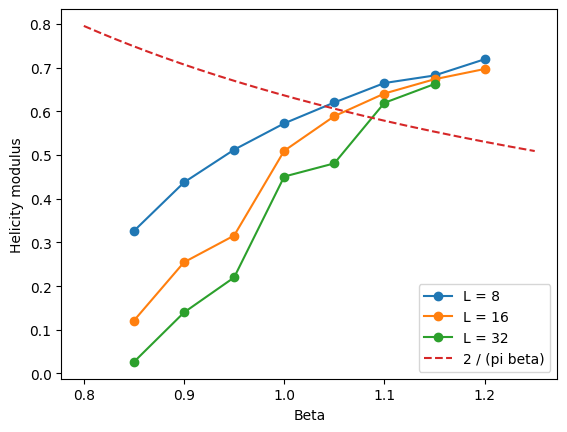

In [71]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        #sort results in increasing beta
        results_L = sorted(results_L, key = lambda result: result['beta'])

        betas_L = np.array([result['beta'] for result in results_L])
        helicity_L = np.array([result['helicity'] for result in results_L])

        plt.plot(betas_L, helicity_L, marker = 'o', label = f'L = {L}')

    #plot the universal BKT jump condition
    beta_jump = np.linspace(0.8, 1.25, 200)

    plt.plot(beta_jump, 2 / (np.pi * beta_jump), '--', label = '2 / (pi beta)')

    plt.xlabel('Beta')
    plt.ylabel('Helicity modulus')

    plt.legend()

    plt.show()

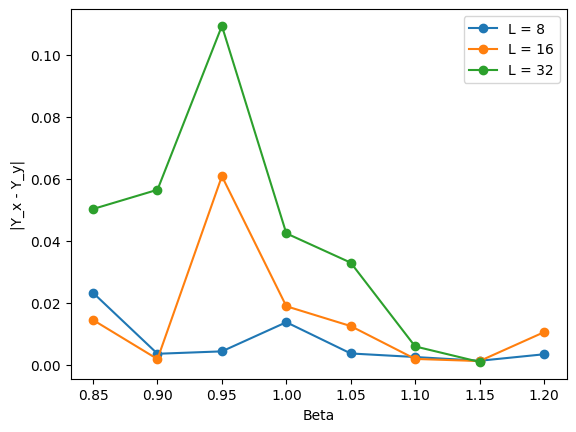

In [75]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        #sort results in increasing beta
        results_L = sorted(results_L, key = lambda result: result['beta'])

        betas_L = np.array([result['beta'] for result in results_L])
        helicity_x_L = np.array([result['helicity_x'] for result in results_L])
        helicity_y_L = np.array([result['helicity_y'] for result in results_L])

        helicity_difference = np.abs(helicity_x_L - helicity_y_L)

        plt.plot(betas_L, helicity_difference, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('|Y_x - Y_y|')

    plt.legend()

    plt.show()

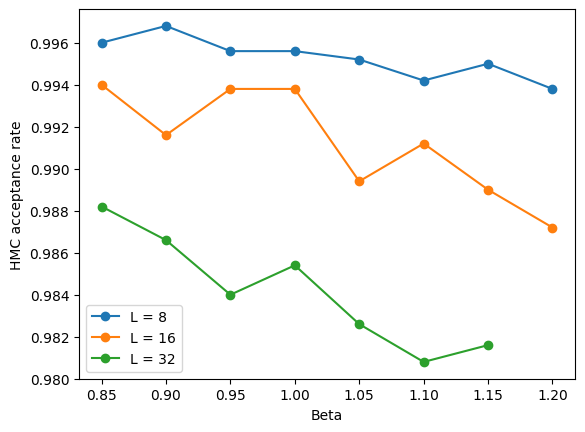

In [73]:
if RUN_LONG_EXPERIMENTS:
    fig, ax = plt.subplots()

    for L in L_values_plot:

        results_L = [result for result in finite_size_results if result['L'] == L]

        betas_L = np.array([result['beta'] for result in results_L])
        acceptance_L = np.array([result['acceptance_rate'] for result in results_L])

        plt.plot(betas_L, acceptance_L, marker = 'o', label = f'L = {L}')

    plt.xlabel('Beta')
    plt.ylabel('HMC acceptance rate')

    plt.legend()

    plt.show()

## Checks for the GitHub preparation changes

These small checks cover the measurement schedule, repeated seeds and invalid
inputs. The original physics assertions above are retained.


In [ ]:
# A small chain is enough to check reproducibility and a non-divisible schedule.
check_options = dict(L=3, start='hot', n_therm=1, n_iter=5, n_leap=1, n_meas=2, seed=123)
check_run_a = run_hmc(quick_action, **check_options)
check_run_b = run_hmc(quick_action, **check_options)
for key in check_run_a:
    if isinstance(check_run_a[key], torch.Tensor):
        assert torch.equal(check_run_a[key], check_run_b[key]), key
    else:
        assert check_run_a[key] == check_run_b[key], key
assert len(check_run_a['energy_per_site']) == 2
assert check_run_a['winding_x'].shape == (2, 3)

# All of these must fail before the simulation starts (including an empty schedule).
for invalid in ({'n_meas': 6}, {'L': 0}, {'n_iter': 2.5}, {'n_leap': True},
                {'n_therm': 0}, {'n_meas': 0}, {'dt': float('nan')},
                {'dt': 0}, {'start': 'warm'}, {'seed': -1}):
    options = {**check_options, **invalid}
    rng_before = torch.random.get_rng_state().clone()
    try:
        run_hmc(quick_action, **options)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected ValueError for {invalid}")
    assert torch.equal(rng_before, torch.random.get_rng_state())

try:
    autocorrelation(torch.ones(8), max_lag=3)
except ValueError:
    pass
else:
    raise AssertionError("A constant series has undefined autocorrelation")
print('Seed, measurement schedule and input checks passed.')


## Scientific notes and limitations

The scientific formulas and original validation tests have been retained during
